# 02 · Exploring the data with an expert eye

We answer our 3 business questions from notebook 01:
1. Which flights will be late or cancelled?
2. Which airlines, airports and times of day are the most reliable?
3. How much is the weather, and how much is the "domino effect" of earlier late flights?

**One rule:** we explore the **training months only (January to September)**. October to December is kept untouched until the models are tested, so nothing we learn here is "peeking" at the answers.

"Late" means *left more than 15 minutes late, or never left (cancelled)*.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
from src import common, viz
from src.stats import day_bootstrap, day_bootstrap_cells, per_day_counts

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from scipy.stats import chi2_contingency, spearmanr
from sklearn.ensemble import HistGradientBoostingRegressor

common.require_processed("flights_clean.parquet")
viz.apply_style()
pd.set_option("display.width", 170)
pd.set_option("display.max_colwidth", 120)

In [2]:
flights = pd.read_parquet(common.PROC / "flights_clean.parquet")
weather = pd.read_parquet(common.PROC / "weather_clean.parquet")
airline_names = (pd.read_csv(common.RAW / "airlines.csv").set_index("carrier")["name"]
                 .str.replace(r"\s+(Inc\.|Co\.|Corporation)$", "", regex=True))

t = flights[flights["part"] != "test"].copy()
t["weekday"] = t["sched_dep_dt"].dt.dayofweek
t["date"] = t["sched_dep_dt"].dt.date
t["hour_band"] = pd.cut(t["hour"], [-1, 11, 17, 24], labels=["Morning (before noon)", "Afternoon (noon to 6 pm)", "Evening (6 pm on)"])
base = t["late_or_cancelled"].mean()
print(f"{len(t):,} training flights | late or cancelled: {base:.1%} | cancelled: {t['cancelled'].mean():.1%}")
print(f"departure delay of flights that left: median {t['dep_delay'].median():.0f} min, mean {t['dep_delay'].mean():.1f} min")

330,883 training flights | late or cancelled: 25.7% | cancelled: 3.2%
departure delay of flights that left: median -2 min, mean 16.4 min


## Tools used below
- **Rate with a confidence interval.** A rate such as "26% late" comes from a sample. A 95% *confidence interval* (Wilson method) is the range in which the true rate very probably lies. A narrow interval means we can trust the number.
- **Chi-square test.** To check that two rates really differ (and are not a coincidence), we use a chi-square test. A *p-value* below 0.001 means a difference this large would almost never appear by chance.
- **Day-level intervals.** Flights on the same day share the same weather and the same knock-on delays, so they are not independent, and a flight-level interval or p-value is too optimistic. The findings below therefore use 95% intervals found by **resampling whole days** (1,000 resamples). The flight-level chi-square is still printed, only for comparison.

In [3]:
def wilson(k, n, z=1.96):
    p = k / n
    centre = (p + z * z / (2 * n)) / (1 + z * z / n)
    half = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return centre - half, centre + half

def rate_table(df, by, y="late_or_cancelled"):
    g = df.groupby(by, observed=True)[y].agg(late="sum", flights="size")
    g["rate"] = g["late"] / g["flights"]
    ci = [wilson(k, n) for k, n in zip(g["late"], g["flights"])]
    g["ci_low"], g["ci_high"] = [c[0] for c in ci], [c[1] for c in ci]
    return g

def chi_square(k1, n1, k2, n2):
    chi2, p, _, _ = chi2_contingency([[k1, n1 - k1], [k2, n2 - k2]], correction=False)
    return chi2, p

def pfmt(p):
    return "p < 0.001" if p < 0.001 else f"p = {p:.3f}"

findings = []
all_days = np.array(sorted(t["date"].unique()), dtype=object)

def day_ci(mask_a, mask_b, statistic, frame=None):
    """95% interval for statistic(rate_a, rate_b), resampling whole days."""
    frame = t if frame is None else frame
    ca = per_day_counts(frame["date"].to_numpy(), frame["late_or_cancelled"].to_numpy(), mask_a, all_days)
    cb = per_day_counts(frame["date"].to_numpy(), frame["late_or_cancelled"].to_numpy(), mask_b, all_days)
    return day_bootstrap(ca, cb, statistic)

## Finding 1 · The risk of delay climbs through the day
Question 1 (when?). We compare the share of late-or-cancelled flights for each scheduled departure hour.

In [4]:
by_hour = rate_table(t[t["hour"].between(5, 22)], "hour")
morning, evening = t[t["hour"].between(6, 8)], t[t["hour"].between(19, 21)]
(km, nm), (ke, ne) = (morning["late_or_cancelled"].sum(), len(morning)), (evening["late_or_cancelled"].sum(), len(evening))
chi_h, p_h = chi_square(km, nm, ke, ne)
lo_m, hi_m = wilson(km, nm); lo_e, hi_e = wilson(ke, ne)
ratio_h = (ke / ne) / (km / nm)
print(f"6-9 am: {km/nm:.1%} (95% CI {lo_m:.1%}-{hi_m:.1%}, {nm:,} flights)")
print(f"7-10 pm: {ke/ne:.1%} (95% CI {lo_e:.1%}-{hi_e:.1%}, {ne:,} flights)")
print(f"ratio {ratio_h:.1f}x | flight-level chi-square = {chi_h:,.0f}, {pfmt(p_h)} (optimistic)")
mask_m, mask_e = t["hour"].between(6, 8).to_numpy(), t["hour"].between(19, 21).to_numpy()
ratio_pt, ratio_lo, ratio_hi = day_ci(mask_m, mask_e, lambda a, b: b / a)
_, dm_lo, dm_hi = day_ci(mask_m, mask_e, lambda a, b: a)
_, de_lo, de_hi = day_ci(mask_m, mask_e, lambda a, b: b)
print(f"resampling whole days: evening is {ratio_pt:.1f}x the morning rate (95% interval {ratio_lo:.1f} to {ratio_hi:.1f}); morning {km/nm:.1%} ({dm_lo:.1%}-{dm_hi:.1%}), evening {ke/ne:.1%} ({de_lo:.1%}-{de_hi:.1%})")
busy = t.groupby(["origin", "time_hour"]).size().rename("n").reset_index()
busy["band"] = pd.cut(busy["time_hour"].dt.hour, [-1, 11, 17, 24], labels=["morning", "afternoon", "evening"])
busy_mean = busy.groupby("band", observed=True)["n"].mean()
print("scheduled departures per airport-hour:", busy_mean.round(1).to_dict())

6-9 am: 13.4% (95% CI 13.2%-13.7%, 66,134 flights)
7-10 pm: 39.6% (95% CI 39.2%-40.0%, 55,808 flights)
ratio 3.0x | flight-level chi-square = 10,973, p < 0.001 (optimistic)
resampling whole days: evening is 3.0x the morning rate (95% interval 2.7 to 3.2); morning 13.4% (12.3%-14.6%), evening 39.6% (36.9%-42.4%)


scheduled departures per airport-hour: {'morning': 23.0, 'afternoon': 24.2, 'evening': 19.3}


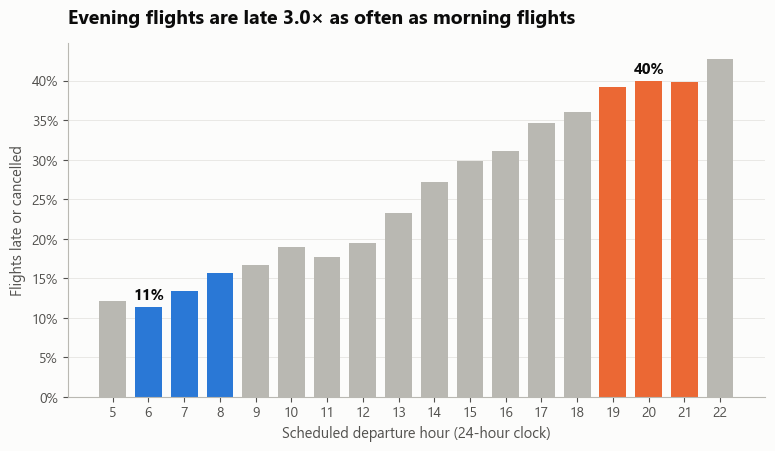

In [5]:
fig, ax = plt.subplots(figsize=(9, 4.6))
colors = [viz.BLUE if h in (6, 7, 8) else viz.ORANGE if h in (19, 20, 21) else viz.GREY for h in by_hour.index]
ax.bar(by_hour.index, by_hour["rate"], color=colors, width=0.75)
ax.set_xticks(by_hour.index)
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
for h in (6, 20):
    ax.annotate(f"{by_hour.loc[h, 'rate']:.0%}", (h, by_hour.loc[h, "rate"]), ha="center", va="bottom", fontsize=11, fontweight="bold", xytext=(0, 3), textcoords="offset points")
ax.set_title(f"Evening flights are late {ratio_h:.1f}× as often as morning flights")
ax.set_xlabel("Scheduled departure hour (24-hour clock)")
ax.set_ylabel("Flights late or cancelled")
chart1 = viz.save_figure(fig, "02_hour.png")
plt.show()

**Reading it.** The share of late flights climbs almost every hour from early morning to late evening. The wait grows from roughly one flight in nine to two in five. The airports are not much busier in the evening (see the departures per airport-hour above), so crowding alone does not explain the climb. One possible reason is delays carried over from earlier flights; finding 2 looks at that.

In [6]:
findings.append(dict(
    finding="The risk of delay climbs through the day",
    number=f"{km/nm:.0%} of flights scheduled between 6 and 9 am are late or cancelled, against {ke/ne:.0%} between 7 and 10 pm ({ratio_h:.1f} times as often).",
    check_type="confidence_interval",
    check_result=f"Resampling whole days (flights on one day are not independent): evening is {ratio_pt:.1f} times the morning rate (95% interval {ratio_lo:.1f} to {ratio_hi:.1f}); morning {km/nm:.1%} ({dm_lo:.1%}-{dm_hi:.1%}), evening {ke/ne:.1%} ({de_lo:.1%}-{de_hi:.1%}). A flight-level chi-square gives {pfmt(p_h)} but is optimistic.",
    action="Offer morning flights to clients with a tight connection or an important meeting, and put evening flights first in the list to warn.",
    chart_file=chart1, looks_strange_at_first=False,
    why=f"Not crowding: airports handle about {busy_mean['morning']:.0f} departures per hour in the morning and {busy_mean['evening']:.0f} in the evening. Delays seem to pile up as the day goes on; finding 2 looks at one way this can happen."))

## Finding 2 · When a plane's earlier flight ran late, its next flight is much more likely to be late (the "domino effect")
Question 3. For each flight we look at the **earlier flight of the same plane on the same day**, but only if that flight had already left at least 2 hours before this one was due (otherwise we would not know it yet when we want to warn the client). We compare the next flight's lateness when the earlier flight was late or on time.

*(This simple version is built carefully and unit-tested in notebook 05.)*

In [7]:
s = t.sort_values(["tailnum", "sched_dep_dt"]).copy()
g = s.groupby(["tailnum", "date"])
s["prev_sched"] = g["sched_dep_dt"].shift()
s["prev_delay"] = g["dep_delay"].shift()
s["prev_left_at"] = s["prev_sched"] + pd.to_timedelta(s["prev_delay"], unit="m")
known = s[s["prev_delay"].notna() & (s["prev_left_at"] <= s["sched_dep_dt"] - pd.Timedelta(hours=common.LEAD_HOURS))].copy()
known["prev_late"] = known["prev_delay"] > common.LATE_MINUTES
print(f"flights with a known earlier flight of the same plane: {len(known):,} of {len(t):,}")

dom = rate_table(known, ["hour_band", "prev_late"])
late_all, ok_all = known[known["prev_late"]], known[~known["prev_late"]]
(k1, n1), (k2, n2) = (late_all["late_or_cancelled"].sum(), len(late_all)), (ok_all["late_or_cancelled"].sum(), len(ok_all))
chi_d, p_d = chi_square(k1, n1, k2, n2)
print(f"earlier flight late: {k1/n1:.1%} late ({n1:,} flights) | earlier flight on time: {k2/n2:.1%} ({n2:,}) | flight-level chi-square = {chi_d:,.0f}, {pfmt(p_d)} (optimistic)")
cl = per_day_counts(known["date"].to_numpy(), known["late_or_cancelled"].to_numpy(), known["prev_late"].to_numpy(), all_days)
co = per_day_counts(known["date"].to_numpy(), known["late_or_cancelled"].to_numpy(), (~known["prev_late"]).to_numpy(), all_days)
gap_pt, gap_lo, gap_hi = day_bootstrap(co, cl, lambda a, b: (b - a) * 100)
print(f"resampling whole days: the gap is {gap_pt:.1f} points (95% interval {gap_lo:.1f} to {gap_hi:.1f})")
print(dom[["flights", "rate"]].round(3).to_string())

flights with a known earlier flight of the same plane: 96,003 of 330,883
earlier flight late: 61.4% late (13,513 flights) | earlier flight on time: 24.7% (82,490) | flight-level chi-square = 7,453, p < 0.001 (optimistic)
resampling whole days: the gap is 36.7 points (95% interval 35.2 to 38.2)
                                    flights   rate
hour_band                prev_late                
Morning (before noon)    False         2371  0.206
                         True           179  0.564
Afternoon (noon to 6 pm) False        42591  0.223
                         True          5338  0.597
Evening (6 pm on)        False        37528  0.277
                         True          7996  0.626


**Is it just a bad day hitting both flights?** A storm or a congested afternoon can make an earlier flight and the next one late at the same time, with no "domino" in between. To check, we compare only flights from **the same day, the same airport and the same part of the day**. Inside each such group we measure the gap between next flights that followed a late earlier flight and those that followed an on-time one, then average the gaps (groups with more flights count more).

In [8]:
cell = known.groupby(["date", "origin", "hour_band", "prev_late"], observed=True)["late_or_cancelled"].agg(rate="mean", n="size").unstack("prev_late").dropna()
rate_late, rate_ok, n_late, n_ok = cell[("rate", True)], cell[("rate", False)], cell[("n", True)], cell[("n", False)]
weight = n_late * n_ok / (n_late + n_ok)
same_day_gap = float(((rate_late - rate_ok) * weight).sum() / weight.sum() * 100)
raw_gap = (k1 / n1 - k2 / n2) * 100
common.REPORTS.mkdir(parents=True, exist_ok=True)
pd.DataFrame([dict(raw_gap_points=round(raw_gap, 1), same_day_gap_points=round(same_day_gap, 1), strata=len(cell), flights=int((n_late + n_ok).sum()))]).to_csv(common.REPORTS / "02_domino_adjusted.csv", index=False)
print(f"gap overall: {raw_gap:.1f} points | gap inside {len(cell):,} same-day, same-airport, same-part-of-day groups: {same_day_gap:.1f} points ({1 - same_day_gap / raw_gap:.0%} smaller)")

gap overall: 36.7 points | gap inside 1,743 same-day, same-airport, same-part-of-day groups: 26.3 points (28% smaller)


**Reading it.** The gap shrinks but does not disappear: a late earlier flight still goes with a clearly higher risk on the same day, at the same airport, at the same time of day. So part of the overall gap is a shared bad day, and part is the earlier flight itself. We can show the link; we cannot prove the cause.

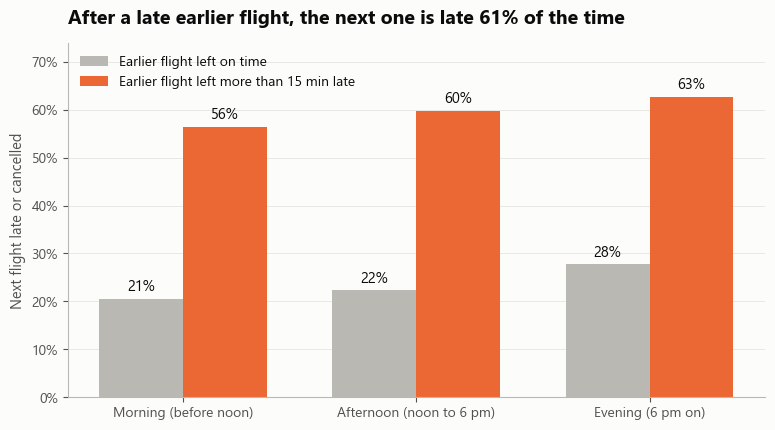

In [9]:
fig, ax = plt.subplots(figsize=(9, 4.6))
bands = list(dom.index.get_level_values(0).unique())
x, w = np.arange(len(bands)), 0.36
on_time = [dom.loc[(b, False), "rate"] for b in bands]
late = [dom.loc[(b, True), "rate"] for b in bands]
b1 = ax.bar(x - w / 2, on_time, w, color=viz.GREY, label="Earlier flight left on time")
b2 = ax.bar(x + w / 2, late, w, color=viz.ORANGE, label="Earlier flight left more than 15 min late")
for bars in (b1, b2):
    for r in bars:
        ax.annotate(f"{r.get_height():.0%}", (r.get_x() + r.get_width() / 2, r.get_height()), ha="center", va="bottom", fontsize=10.5, xytext=(0, 3), textcoords="offset points")
ax.set_xticks(x); ax.set_xticklabels(bands)
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_ylim(0, max(late) * 1.18)
ax.legend(loc="upper left")
ax.set_title(f"After a late earlier flight, the next one is late {k1/n1:.0%} of the time")
ax.set_ylabel("Next flight late or cancelled")
chart2 = viz.save_figure(fig, "02_domino.png")
plt.show()

In [10]:
findings.append(dict(
    finding="When a plane's earlier flight ran late, its next flight is much more likely to be late (the domino effect)",
    number=f"When the same plane's earlier flight left more than 15 minutes late, {k1/n1:.0%} of the next flights are late or cancelled, against {k2/n2:.0%} when it left on time.",
    check_type="confidence_interval",
    check_result=f"Resampling whole days: the gap is {gap_pt:.0f} points (95% interval {gap_lo:.0f} to {gap_hi:.0f}); {n1:,} flights after a late flight, {n2:,} after an on-time one. Within the same day, airport and part of the day the gap is {same_day_gap:.0f} points against {raw_gap:.0f} overall.",
    action="Two hours before departure, look at the same plane's earlier flights today. If one ran late, warn the client early and prepare a backup.",
    chart_file=chart2, looks_strange_at_first=False,
    why=f"A delay can travel forward because planes, crews and gates are shared, but part of the gap is a bad day hitting both flights: within the same day, airport and part of the day the gap is {same_day_gap:.0f} points instead of {raw_gap:.0f}. It shows in the morning, afternoon and evening alike (see the chart), so it is not just the time-of-day effect. We can show the link, not prove the cause."))

## Finding 3 · Airlines differ a lot, and airport and time of day do not explain it
Question 2 (who?). We keep the airlines with at least 5,000 flights, so the rates are solid.
Then we ask: *could the gap just come from where and when each airline flies?* We compare each airline with what we would expect if its flights were as late as the average flight **from the same airport in the same part of the day**. A ratio of 1.00 means "as expected".

In [11]:
big = t.groupby("carrier").size()
big = big[big >= 5000].index
t["expected"] = t.groupby(["origin", "hour_band"], observed=True)["late_or_cancelled"].transform("mean")
air = rate_table(t[t["carrier"].isin(big)], "carrier")
exp = t[t["carrier"].isin(big)].groupby("carrier")["expected"].mean()
air["expected"] = exp
air["ratio"] = air["rate"] / air["expected"]
air["airline"] = air.index.map(airline_names)
air = air.sort_values("rate")
best, worst = air.index[0], air.index[-1]
chi_a, p_a = chi_square(air.loc[best, "late"], air.loc[best, "flights"], air.loc[worst, "late"], air.loc[worst, "flights"])
print(air[["airline", "flights", "rate", "ci_low", "ci_high", "expected", "ratio"]].round(3).to_string())
print(f"best vs worst: flight-level chi-square = {chi_a:,.0f}, {pfmt(p_a)} (optimistic)")
ratio_a, ratio_a_lo, ratio_a_hi = day_ci((t["carrier"] == best).to_numpy(), (t["carrier"] == worst).to_numpy(), lambda a, b: b / a)
print(f"resampling whole days: the worst airline's rate is {ratio_a:.1f}x the best airline's (95% interval {ratio_a_lo:.1f} to {ratio_a_hi:.1f})")

                    airline  flights   rate  ci_low  ci_high  expected  ratio
carrier                                                                      
YX         Republic Airline    69609  0.176   0.174    0.179     0.262  0.674
9E             Endeavor Air    40538  0.210   0.206    0.214     0.251  0.835
AA        American Airlines    30925  0.211   0.206    0.215     0.231  0.914
AS          Alaska Airlines     5882  0.227   0.216    0.238     0.274  0.828
DL          Delta Air Lines    45585  0.249   0.245    0.253     0.245  1.019
NK         Spirit Air Lines    10857  0.299   0.291    0.308     0.258  1.159
WN       Southwest Airlines     9267  0.299   0.290    0.309     0.225  1.330
UA         United Air Lines    60411  0.317   0.314    0.321     0.280  1.132
B6          JetBlue Airways    51252  0.351   0.347    0.355     0.258  1.359
best vs worst: flight-level chi-square = 4,778, p < 0.001 (optimistic)
resampling whole days: the worst airline's rate is 2.0x the best airlin

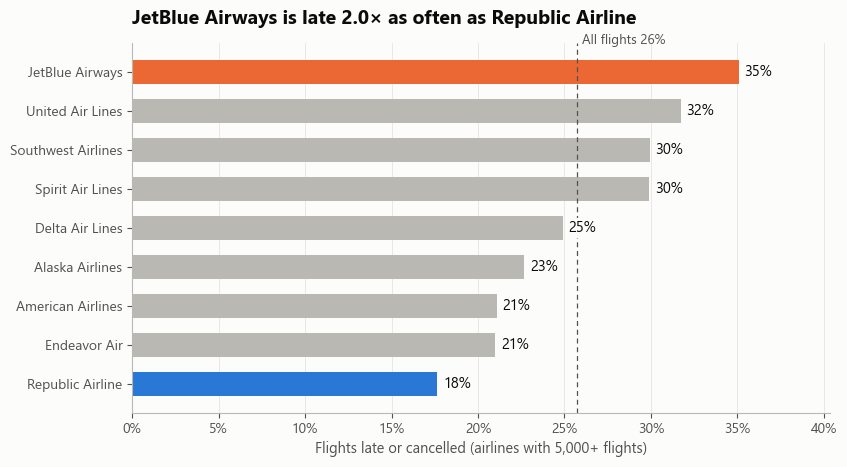

In [12]:
fig, ax = plt.subplots(figsize=(9, 4.8))
colors = [viz.BLUE if c == best else viz.ORANGE if c == worst else viz.GREY for c in air.index]
ax.barh(air["airline"], air["rate"], color=colors, height=0.62)
for y_, r in zip(air["airline"], air["rate"]):
    ax.annotate(f"{r:.0%}", (r, y_), ha="left", va="center", fontsize=10.5, xytext=(4, 0), textcoords="offset points",
                bbox=dict(facecolor=viz.SURFACE, edgecolor="none", pad=1.5), zorder=5)
ax.axvline(base, color=viz.INK_2, linewidth=0.9, linestyle=(0, (4, 3)))
ax.annotate(f"All flights {base:.0%}", (base, len(air) - 0.35), ha="left", va="bottom", fontsize=9.5, color=viz.INK_2, xytext=(4, 0), textcoords="offset points")
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.grid(axis="y", visible=False); ax.grid(axis="x")
ax.set_xlim(0, air["rate"].max() * 1.15)
ax.set_title(f"{air.loc[worst, 'airline']} is late {air.loc[worst, 'rate'] / air.loc[best, 'rate']:.1f}× as often as {air.loc[best, 'airline']}")
ax.set_xlabel("Flights late or cancelled (airlines with 5,000+ flights)")
chart3 = viz.save_figure(fig, "02_airlines.png")
plt.show()

In [13]:
findings.append(dict(
    finding="Airlines differ a lot in reliability",
    number=f"Among the {len(air)} biggest airlines, {air.loc[best, 'airline']} has {air.loc[best, 'rate']:.0%} of flights late or cancelled and {air.loc[worst, 'airline']} has {air.loc[worst, 'rate']:.0%}.",
    check_type="confidence_interval",
    check_result=f"Resampling whole days: the worst airline's rate is {ratio_a:.1f} times the best airline's (95% interval {ratio_a_lo:.1f} to {ratio_a_hi:.1f}); {air.loc[best, 'airline']} {air.loc[best, 'rate']:.1%}, {air.loc[worst, 'airline']} {air.loc[worst, 'rate']:.1%}. The best and the worst were picked from the same data, so the size of the gap is somewhat flattering; the gap is wide enough for the order to hold.",
    action="When a client has a tight connection, prefer the more reliable airlines; warn clients on the least reliable ones earlier.",
    chart_file=chart3, looks_strange_at_first=False,
    why=f"Compared only with flights from the same airport in the same part of the day, {air.loc[worst, 'airline']} runs at {air.loc[worst, 'ratio']:.2f} times the expected rate and {air.loc[best, 'airline']} at {air.loc[best, 'ratio']:.2f} (1.00 = as expected). A ratio far from 1.00 means airport and time of day do not explain the gap."))

## Finding 4 · A late earlier flight goes with a bigger jump in risk than everyday bad weather does
Question 3. We attach the weather at the airport in the scheduled departure hour. (Here we only *explain* the past, so using that hour is fine; the models later use the reading from 2 hours before.) "Bad weather" means rain or snow, **or** visibility under 3 miles, **or** wind gusts of 25 mph or more.

In [14]:
m = t.merge(weather, on=["origin", "time_hour"], how="left")
assert len(m) == len(t)
m["bad_weather"] = (m["precip"] > 0) | (m["visib"] < 3) | (m["wind_gust"] >= 25)
conds = {"rain or snow": m["precip"] > 0, "visibility under 3 miles": m["visib"] < 3, "gusts of 25 mph or more": m["wind_gust"] >= 25, "any of the three": m["bad_weather"]}
for name, mask in conds.items():
    a, b = m[mask], m[~mask]
    chi_, p_ = chi_square(a["late_or_cancelled"].sum(), len(a), b["late_or_cancelled"].sum(), len(b))
    print(f"{name:26s} {a['late_or_cancelled'].mean():5.1%} late vs {b['late_or_cancelled'].mean():5.1%} otherwise | {len(a):>7,} flights | chi-square = {chi_:,.0f}, {pfmt(p_)}")
bad, calm = m[m["bad_weather"]], m[~m["bad_weather"]]
chi_w, p_w = chi_square(bad["late_or_cancelled"].sum(), len(bad), calm["late_or_cancelled"].sum(), len(calm))
gap_w, gap_w_lo, gap_w_hi = day_ci((~m["bad_weather"]).to_numpy(), m["bad_weather"].to_numpy(), lambda a, b: (b - a) * 100, frame=m)
print(f"resampling whole days: bad weather adds {gap_w:.1f} points (95% interval {gap_w_lo:.1f} to {gap_w_hi:.1f})")

rain or snow               36.7% late vs 24.1% otherwise |  43,434 flights | chi-square = 3,152, p < 0.001
visibility under 3 miles   41.1% late vs 25.3% otherwise |   8,833 flights | chi-square = 1,125, p < 0.001
gusts of 25 mph or more    35.1% late vs 25.4% otherwise |  10,911 flights | chi-square = 520, p < 0.001
any of the three           35.8% late vs 23.7% otherwise |  55,646 flights | chi-square = 3,544, p < 0.001


resampling whole days: bad weather adds 12.1 points (95% interval 8.8 to 15.4)


To compare weather with the domino effect fairly, we put both side by side for the flights with a known earlier flight.

In [15]:
k = known.merge(weather, on=["origin", "time_hour"], how="left")
k["bad_weather"] = (k["precip"] > 0) | (k["visib"] < 3) | (k["wind_gust"] >= 25)
two = rate_table(k, ["prev_late", "bad_weather"])
print(two[["flights", "rate"]].round(3).to_string())
weather_points = (two.loc[(False, True), "rate"] - two.loc[(False, False), "rate"]) * 100
domino_points = (two.loc[(True, False), "rate"] - two.loc[(False, False), "rate"]) * 100
print(f"bad weather adds {weather_points:.0f} points; a late earlier flight adds {domino_points:.0f} points (when the other factor is absent)")
# The title compares the two jumps, so the check is an interval for their difference, resampling whole days (the same days in every cell)
cell_counts = [per_day_counts(k["date"].to_numpy(), k["late_or_cancelled"].to_numpy(), ((k["prev_late"] == late_) & (k["bad_weather"] == bad_)).to_numpy(), all_days)
               for late_, bad_ in [(False, False), (True, False), (False, True)]]
gap_jumps, gap_jumps_lo, gap_jumps_hi = day_bootstrap_cells(cell_counts, lambda r: ((r[1] - r[0]) - (r[2] - r[0])) * 100)
print(f"resampling whole days: the late earlier flight's jump is {gap_jumps:.0f} points bigger than the weather jump (95% interval {gap_jumps_lo:.0f} to {gap_jumps_hi:.0f})")

# How much does the answer depend on what we call "bad weather"? Our definition is broad (any rain or snow, visibility under 3 miles, or gusts of 25 mph or more), and flights with
# a missing gust reading count as calm. With stricter definitions the weather jump gets larger, but it covers very few flights.
def weather_jump(mask):
    on_time = k[~k["prev_late"]]
    hit = on_time.loc[mask[on_time.index], "late_or_cancelled"]
    return (hit.mean() - on_time.loc[~mask[on_time.index], "late_or_cancelled"].mean()) * 100, len(hit)
stricter = {"visibility under 1 mile": k["visib"] < 1, "gusts of 35 mph or more": k["wind_gust"] >= 35, "rain or snow of 0.1 inch or more": k["precip"] >= 0.1}
sensitivity = {name: weather_jump(mask) for name, mask in stricter.items()}
sensitivity_text = "; ".join(f"{name}: +{jump:.0f} points, {n:,} flights" for name, (jump, n) in sensitivity.items())
print("stricter weather definitions (flights whose earlier flight left on time):", sensitivity_text)
print(f"flights with a missing gust reading counted as calm: {int(k['wind_gust'].isna().sum()):,} of {len(k):,}")

                       flights   rate
prev_late bad_weather                
False     False          69985  0.219
          True           12505  0.403
True      False          10563  0.582
          True            2950  0.729
bad weather adds 18 points; a late earlier flight adds 36 points (when the other factor is absent)
resampling whole days: the late earlier flight's jump is 18 points bigger than the weather jump (95% interval 13 to 22)
stricter weather definitions (flights whose earlier flight left on time): visibility under 1 mile: +29 points, 149 flights; gusts of 35 mph or more: +23 points, 163 flights; rain or snow of 0.1 inch or more: +64 points, 80 flights
flights with a missing gust reading counted as calm: 4,828 of 96,003


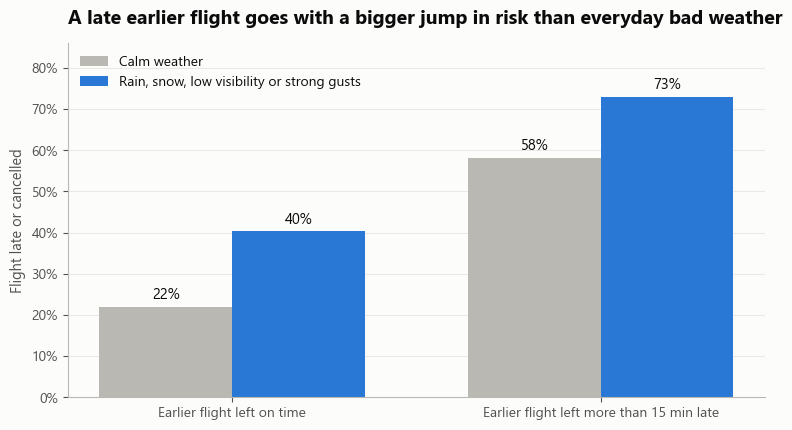

In [16]:
fig, ax = plt.subplots(figsize=(9, 4.6))
x, w = np.arange(2), 0.36
calm_r = [two.loc[(False, False), "rate"], two.loc[(True, False), "rate"]]
bad_r = [two.loc[(False, True), "rate"], two.loc[(True, True), "rate"]]
b1 = ax.bar(x - w / 2, calm_r, w, color=viz.GREY, label="Calm weather")
b2 = ax.bar(x + w / 2, bad_r, w, color=viz.BLUE, label="Rain, snow, low visibility or strong gusts")
for bars in (b1, b2):
    for r in bars:
        ax.annotate(f"{r.get_height():.0%}", (r.get_x() + r.get_width() / 2, r.get_height()), ha="center", va="bottom", fontsize=10.5, xytext=(0, 3), textcoords="offset points")
ax.set_xticks(x); ax.set_xticklabels(["Earlier flight left on time", "Earlier flight left more than 15 min late"])
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_ylim(0, max(bad_r) * 1.18)
ax.legend(loc="upper left")
ax.set_title("A late earlier flight goes with a bigger jump in risk than everyday bad weather")
ax.set_ylabel("Flight late or cancelled")
chart4 = viz.save_figure(fig, "02_weather.png")
plt.show()

In [17]:
findings.append(dict(
    finding="A late earlier flight goes with a bigger jump in risk than everyday bad weather does",
    number=f"In bad weather {bad['late_or_cancelled'].mean():.0%} of flights are late or cancelled, against {calm['late_or_cancelled'].mean():.0%} in calm weather. Among flights whose plane had already flown earlier that day, a late earlier flight adds {domino_points:.0f} points and bad weather adds {weather_points:.0f}.",
    check_type="confidence_interval",
    check_result=f"Resampling whole days: the late earlier flight's jump is {gap_jumps:.0f} points bigger than the bad-weather jump (the difference between the two jumps, 95% interval {gap_jumps_lo:.0f} to {gap_jumps_hi:.0f}); on its own, bad weather adds {gap_w:.0f} points to the rate over all flights (95% interval {gap_w_lo:.0f} to {gap_w_hi:.0f}; {len(bad):,} flights in bad weather, {len(calm):,} in calm weather).",
    action="Use the weather report as a trigger to warn clients ahead of a stormy day, and the earlier-flight check as the stronger signal for individual flights.",
    chart_file=chart4, looks_strange_at_first=False,
    why=f"Bad weather cuts the number of flights an airport can handle, so queues form. A late earlier flight goes with a bigger jump in risk in these data, although part of that jump is a shared bad day (finding 2). We can compare the two jumps, but not say what causes each. The comparison is with everyday bad weather as defined above (flights with a missing gust reading count as calm). With stricter definitions the weather jump gets larger but covers very few flights ({sensitivity_text}), against {domino_points:.0f} points for a late earlier flight."))

## Finding 5 · Cancellations come in waves on a few stormy days (and summer is worse than winter)
This one looks **strange at first**: we would expect snow in January and February to cancel the most flights. We check the months, then the worst days.

In [18]:
monthly = t.groupby("month").agg(cancelled=("cancelled", "sum"), flights=("cancelled", "size"))
monthly["rate"] = monthly["cancelled"] / monthly["flights"]
winter = t[t["month"].isin([1, 2])]["cancelled"].mean()
july = monthly.loc[7, "rate"]
per_day = t[t["cancelled"] == 1].groupby("date").size().sort_values(ascending=False)
worst_days = list(per_day.head(10).index)
share10 = per_day.head(10).sum() / per_day.sum()
print("cancelled share by month:", monthly["rate"].round(3).to_dict())
print(f"days with at least one cancellation: {len(per_day)} of {t['date'].nunique()} | the 10 worst days hold {share10:.0%} of all cancellations")
print("worst days:", {str(d): int(n) for d, n in per_day.head(5).items()})

cancelled share by month: {1: 0.014, 2: 0.016, 3: 0.015, 4: 0.028, 5: 0.004, 6: 0.06, 7: 0.087, 8: 0.017, 9: 0.05}
days with at least one cancellation: 265 of 273 | the 10 worst days hold 35% of all cancellations
worst days: {'2023-06-27': 503, '2023-07-09': 491, '2023-06-26': 481, '2023-07-16': 399, '2023-09-10': 375}


Does the weather at our three airports explain those days? Flights on one day share the same weather, so we compare **days**: for each day we take the share of cancelled flights and the weather, and measure how closely they rise and fall together (a *rank correlation*: 0 = unrelated, 1 = always together).

In [19]:
day = m.groupby("date").agg(flights=("cancelled", "size"), cancelled=("cancelled", "sum"), rain_share=("precip", lambda s: (s > 0).mean()),
                            heaviest_rain=("precip", "max"), gust25=("wind_gust", lambda s: (s >= 25).mean()))
day["rate"] = day["cancelled"] / day["flights"]
rho, p_rho = spearmanr(day["rate"], day["heaviest_rain"])
worst5 = day.sort_values("cancelled", ascending=False).head(5)
quiet_rain = int((worst5["rain_share"] < 0.30).sum())
no_gust = int((worst5["gust25"] == 0).sum())
print(f"{len(day)} days | rank correlation between daily cancellation rate and the heaviest hourly rain: {rho:.2f} ({pfmt(p_rho)})")
print(worst5[["cancelled", "rate", "rain_share", "gust25"]].round(3).to_string())
print(f"of the 5 worst days: {quiet_rain} had rain at the time of fewer than 3 in 10 flights, {no_gust} had no gusts of 25 mph or more")

273 days | rank correlation between daily cancellation rate and the heaviest hourly rain: 0.39 (p < 0.001)
            cancelled   rate  rain_share  gust25
date                                            
2023-06-27        503  0.410       0.217     0.0
2023-07-09        491  0.429       0.142     0.0
2023-06-26        481  0.387       0.241     0.0
2023-07-16        399  0.343       0.730     0.0
2023-09-10        375  0.327       0.269     0.0
of the 5 worst days: 4 had rain at the time of fewer than 3 in 10 flights, 5 had no gusts of 25 mph or more


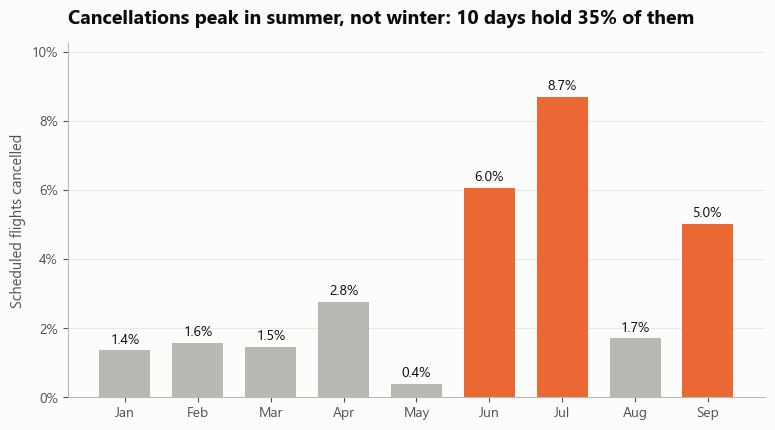

In [20]:
fig, ax = plt.subplots(figsize=(9, 4.6))
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep"]
top3 = set(monthly["rate"].nlargest(3).index)
ax.bar(months, monthly["rate"], color=[viz.ORANGE if mo in top3 else viz.GREY for mo in monthly.index], width=0.7)
for mo, r in zip(months, monthly["rate"]):
    ax.annotate(f"{r:.1%}", (mo, r), ha="center", va="bottom", fontsize=10, xytext=(0, 3), textcoords="offset points")
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_ylim(0, monthly["rate"].max() * 1.18)
ax.set_title(f"Cancellations peak in summer, not winter: 10 days hold {share10:.0%} of them")
ax.set_ylabel("Scheduled flights cancelled")
chart5 = viz.save_figure(fig, "02_cancellations.png")
plt.show()

In [21]:
findings.append(dict(
    finding="Cancellations come in waves on a few days, mostly in summer",
    number=f"The 10 worst days hold {share10:.0%} of all cancellations from January to September. July had {july:.1%} of flights cancelled against {winter:.1%} in January and February.",
    check_type="rank_correlation",
    check_result=f"Across {len(day)} days, the daily cancellation rate and the heaviest hourly rain at the airports rise together only moderately: rank correlation {rho:.2f}, {pfmt(p_rho)}.",
    action="Do not wait for winter: watch for summer storm days. Keep backup options for clients ready, and rebook early when airlines or air-traffic alerts announce disruption, since New York weather alone does not predict these days.",
    chart_file=chart5, looks_strange_at_first=True,
    why=f"Odd at first, since snow is the usual suspect. The weather at our three airports explains only part of it: daily cancellations rise with rain (rank correlation {rho:.2f}), but {quiet_rain} of the 5 worst days had rain at the time of fewer than 3 in 10 flights and {no_gust} had no gusts of 25 mph at all. Storms elsewhere on the routes or air-traffic limits are not in our data, so that remains a guess. The data cannot tell us why winter 2023 was calmer."))

## Our 5 best findings
Each one has a number, a check that it is real, a chart and an action for the business. They are saved in `reports/02_findings.csv`.

In [22]:
out = pd.DataFrame(findings)
out.insert(0, "rank", range(1, len(out) + 1))
common.REPORTS.mkdir(parents=True, exist_ok=True)
out.to_csv(common.REPORTS / "02_findings.csv", index=False)

def whole_percent(x):
    return int(f"{x:.0%}".rstrip("%"))      # exactly the whole percent written in the sentences

# the numbers the presentation quotes, as numbers (the slides read them by name, not by cutting them out of the sentences)
pd.DataFrame([("morning_pct", whole_percent(km / nm)), ("evening_pct", whole_percent(ke / ne)),
              ("late_plane_pct", whole_percent(k1 / n1)), ("ok_plane_pct", whole_percent(k2 / n2)),
              ("airline_best", air.loc[best, "airline"]), ("best_pct", whole_percent(air.loc[best, "rate"])),
              ("airline_worst", air.loc[worst, "airline"]), ("worst_pct", whole_percent(air.loc[worst, "rate"])),
              ("plane_points", int(f"{domino_points:.0f}")), ("weather_points", int(f"{weather_points:.0f}")),
              ("ten_days_pct", whole_percent(share10))], columns=["name", "value"]).to_csv(common.REPORTS / "02_key_numbers.csv", index=False)
for r in out.itertuples():
    print(f"{r.rank}. {r.finding}\n   {r.number}\n   Check: {r.check_result}\n   Do: {r.action}\n")

1. The risk of delay climbs through the day
   13% of flights scheduled between 6 and 9 am are late or cancelled, against 40% between 7 and 10 pm (3.0 times as often).
   Check: Resampling whole days (flights on one day are not independent): evening is 3.0 times the morning rate (95% interval 2.7 to 3.2); morning 13.4% (12.3%-14.6%), evening 39.6% (36.9%-42.4%). A flight-level chi-square gives p < 0.001 but is optimistic.
   Do: Offer morning flights to clients with a tight connection or an important meeting, and put evening flights first in the list to warn.

2. When a plane's earlier flight ran late, its next flight is much more likely to be late (the domino effect)
   When the same plane's earlier flight left more than 15 minutes late, 61% of the next flights are late or cancelled, against 25% when it left on time.
   Check: Resampling whole days: the gap is 37 points (95% interval 35 to 38); 13,513 flights after a late flight, 82,490 after an on-time one. Within the same day, airpo

## Choosing the second prediction
Our first prediction is *"will this flight be late or cancelled?"*. For the second we need a different question that a model can answer and the business can use.

**Candidate A: how many minutes late will this flight leave?** (a number). Use: tell clients to expect a long delay and check their connections.
**Candidate B: will this flight be cancelled?** Rejected: only 224 flights were cancelled in the test months (0.2%) against 3.2% in training, too few to score a model honestly. (We looked at the overall rates of the test months when designing the project; this is disclosed in the second brain, D-004 and D-025. The models never train on them or are tuned on them.)

**Rule (decision D-013), set before the probe was run:** choose A unless a quick model that only uses the schedule (hour, weekday, airline, airport, distance) cannot beat the dumb answer "always predict the usual delay" by at least 3% on the validation months (July to September). If it cannot, we fall back to "more than 60 minutes late? yes or no".

**One deviation, disclosed.** The implementation plan also listed `month` among the probe columns. We left it out because the validation months (July to September) never appear among the fit months (January to June), so a model cannot learn what they mean; it is the same reason `month` is not a feature in notebook 05. We decided this while writing this notebook, before the probe was run (there is no timestamp to prove it). To be transparent, the cell below also runs the probe **with** `month`.

In [23]:
dep = t[t["dep_delay"].notna()].copy()
cols = ["hour", "weekday", "distance", "carrier", "origin"]
X = dep[cols].copy()
X["carrier"], X["origin"] = X["carrier"].astype("category"), X["origin"].astype("category")
fit_m, valid_m = (dep["part"] == "fit").to_numpy(), (dep["part"] == "valid").to_numpy()
y_dep = dep["dep_delay"]
usual = y_dep[fit_m].median()
mae_dumb = (y_dep[valid_m] - usual).abs().mean()
probe = HistGradientBoostingRegressor(loss="absolute_error", categorical_features="from_dtype", random_state=common.SEED)
probe.fit(X[fit_m], y_dep[fit_m])
mae_model = (y_dep[valid_m] - probe.predict(X[valid_m])).abs().mean()
gain = 1 - mae_model / mae_dumb
print(f"usual delay in the fit months: {usual:.0f} min")
print(f"average error on the validation months: dumb answer {mae_dumb:.2f} min | schedule-only model {mae_model:.2f} min | {gain:.1%} lower")

def probe_gain(columns):
    Xp = dep[columns].copy()
    Xp["carrier"], Xp["origin"] = Xp["carrier"].astype("category"), Xp["origin"].astype("category")
    m = HistGradientBoostingRegressor(loss="absolute_error", categorical_features="from_dtype", random_state=common.SEED).fit(Xp[fit_m], y_dep[fit_m])
    return 1 - (y_dep[valid_m] - m.predict(Xp[valid_m])).abs().mean() / mae_dumb

gain_with_month = probe_gain(cols + ["month"])
print(f"for transparency, the same probe with the month added: {gain_with_month:.1%} lower")
if (gain >= 0.03) != (gain_with_month >= 0.03):
    print("The two versions fall on opposite sides of the 3% line: the choice of the second prediction is a close call.")

usual delay in the fit months: -2 min
average error on the validation months: dumb answer 26.12 min | schedule-only model 25.22 min | 3.4% lower


for transparency, the same probe with the month added: 2.0% lower
The two versions fall on opposite sides of the 3% line: the choice of the second prediction is a close call.


In [24]:
choice = "minutes_late" if gain >= 0.03 else "over_60_min"
if choice == "minutes_late":
    row = dict(choice=choice, target="dep_delay in minutes, for flights that left", metric="average error in minutes (MAE)",
               dumb_answer=f"always predict the usual delay of the training months ({usual:.0f} minutes)",
               reason=f"On the validation months a schedule-only model is wrong by {mae_model:.1f} min on average against {mae_dumb:.1f} for the dumb answer, {gain:.1%} lower (the rule asks for at least 3%). Use: tell clients to expect a long delay and check their connections.")
else:
    row = dict(choice=choice, target="1 if the flight left more than 60 minutes late", metric="PR-AUC (precision vs recall)",
               dumb_answer="nobody is more than 60 minutes late",
               reason=f"A schedule-only model beats the dumb answer by only {gain:.1%} (< 3%), so we predict very long delays (over 60 minutes) as a yes-or-no question.")
row.update(probe_gain=round(float(gain), 4), probe_gain_with_month=round(float(gain_with_month), 4))
pd.DataFrame([row]).to_csv(common.REPORTS / "02_second_prediction.csv", index=False)
print(row["choice"], "|", row["reason"])

minutes_late | On the validation months a schedule-only model is wrong by 25.2 min on average against 26.1 for the dumb answer, 3.4% lower (the rule asks for at least 3%). Use: tell clients to expect a long delay and check their connections.


## What we take to the next notebooks
- **Groups (notebook 03):** destination airports can be grouped by their delay pattern (hour effect, share cancelled...).
- **Features (notebook 05):** the hour of the day, the earlier flight of the same plane, the airline, the airport and the weather are the columns most worth building.
- **Second prediction:** the choice above, with its question, its dumb answer and its use.